<h3>ME 360 Monte Carlo Integration Project</h3>
Group members: Ken Aoki, Jaycee Hasegawa, Zi Hao Huang, Carl Mercado, Yongjun Yu

The numerical work for the project consists of three parts:
- Solver: You need to make an algorithm that is general enough to solve the numerical problem
for any parameter values within some range.
- Visualization: You need to write code that visualizes your solution in terms of graphs, diagrams, or animations appropriate to the topic.
- Parameter sweep: Each problem has either slightly or dramatically different solutions depending on the value of a parameter you choose. For each project, you need to sweep across a
reasonable range of parameters. In order to balance the workload with group size, I expect the
number of parameter sweeps to be one less than group size, e.g. a group of four students needs to
report at least three parameter sweeps.

In [ ]:
import random
import numpy as np
import math

import matplotlib.pyplot as plt
from matplotlib import rc

plt.rcParams['xtick.labelsize']=20      # change the tick label size for x axis
plt.rcParams['ytick.labelsize']=20      # change the tick label size for x axis
plt.rcParams['axes.linewidth']=3        # change the line width of the axis
plt.rcParams['xtick.major.width'] = 3   # change the tick line width of x axis
plt.rcParams['ytick.major.width'] = 3   # change the tick line width of y axis
rc('text', usetex=False)                # disable LaTeX rendering in plots
rc('font',**{'family':'DejaVu Sans'})   # set the font of the plot to be DejaVu Sans

<h4>Monte Carlo Integration Method to Estimate Pi</h4>
Code originally created by Balthazar Courvoisier and posted on Quants Quest website
<br>
(https://quants.quest/PiEstimation/)
<br>
<br>
Specific question: How does the error of the Monte Carlo integration method change based on the number of samples taken when estimating pi?

In [49]:
def est_pi(iter):
    
    n = int(iter)  # number of simulations
    x1 = np.random.uniform(-1, 1, n)
    x2 = np.random.uniform(-1, 1, n)
    
    # Check which points fall inside the unit circle
    inside_circle = x1**2 + x2**2 <= 1
    
    # Estimate of pi
    pi_estimate = 4 * inside_circle.mean()

    return pi

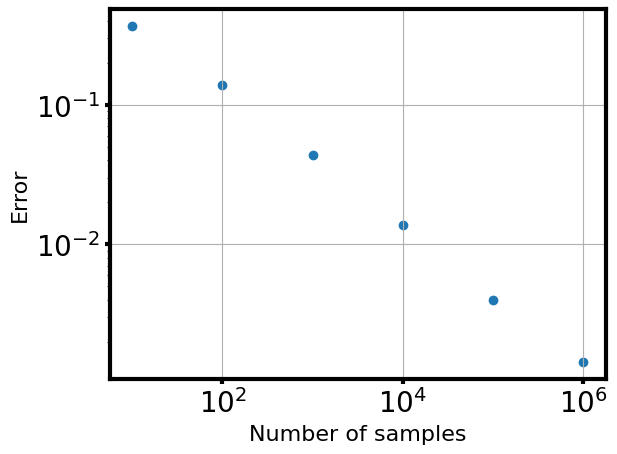

In [56]:
num_trials = 100
samples = [1e1, 1e2, 1e3, 1e4, 1e5, 1e6]
error = []
all_errors = []

for row in range(num_trials):
    for col in samples:
        error.append(abs(est_pi(col)-math.pi))
    all_errors.append(error)
    error = []

avg_error = np.mean(all_errors, axis=0)

plt.scatter(samples, avg_error)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Number of samples', fontsize = 16)
plt.ylabel('Error', fontsize = 16)
plt.grid()

<h4>Monte Carlo Integration Method with Variable Functions</h4>
Code originally created by Saikat Sahana and posted on Geeks for Geeks website
<br>
(https://www.geeksforgeeks.org/python/monte-carlo-integration-in-python/)
<br>
<br>
Specific question: How does the number of samples required to achieve a given tolerance change based on the function?

In [85]:
def fun1(x):
    return np.sin(x)

def fun2(x):
    return np.exp(x)

def fun3(x):
    return np.power(x,2) + 4*x + 4

In [73]:
def mci(f, a, b, N):
    x_random = np.random.uniform(a, b, N)
    estimate = (b - a) * np.mean(f(x_random))
    
    return estimate

In [79]:
def num_samples(f, ground_truth, a, b, tol, max_iter=10e6):
    N = 1
    while N <= max_iter:
        if abs(mci(f, a, b, N) - ground_truth) <= tol:
            return N
        N += 1
    raise ValueError("Maximum number of iterations reached before given solution tolerance was achieved")

In [100]:
num_trials = 100
a = 0
b = 1

In [99]:
# Function 1: sin(x)
samples = []

ground_truth = -math.cos(b) + math.cos(a)

for i in range(num_trials):
    samples.append(num_samples(fun1, ground_truth, a, b, 0.5e-4))

avg_samples_f1 = np.mean(samples)

print(avg_samples_f1)

420.3


In [96]:
# Function 2: e^x
samples = []

ground_truth = math.e**b - math.e**a

for i in range(num_trials):
    samples.append(num_samples(fun2, ground_truth, a, b, 0.5e-4))

avg_samples_f2 = np.mean(samples)

print(avg_samples_f2)

575.44


In [101]:
# Function 3: x^2 + 4x + 4
samples = []

ground_truth = (1/3)*b**3 + 2*b**2 + 4*b - ((1/3)*a**3 + 2*a**2 + 4*a)

for i in range(num_trials):
    samples.append(num_samples(fun3, ground_truth, a, b, 0.5e-4))

avg_samples_f3 = np.mean(samples)

print(avg_samples_f3)

1300.29
